# Notebook 01 - Datos de XM y MDP de la batería

Proyecto final SI3003 - Inteligencia Artificial (EAFIT 2026-2)
Jerónimo Castaño Herrera, Emanuel Gonzalez Florez, Jerónimo Zapata Cuadros

La idea: una batería pequeña conectada a la red que compra energía en la bolsa cuando está barata y la vende cuando está cara. Usamos el precio de bolsa nacional horario de XM (datos reales) y resolvemos la operación como un MDP con **iteración de valor** implementada por nosotros (`src/mdp.py`).

Primero hay que correr `python src/descargar_datos.py` para tener `data/precio_bolsa.csv` (ya viene en el repo).

In [1]:
import os
os.chdir("..")  # para que las rutas data/... funcionen desde la carpeta notebooks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import mdp

df = mdp.cargar_precios()
print(df.shape)
df.head()

(33600, 4)


,fecha,hora,precio,relativo
0,2023-01-01,0,510.90133,1.0
1,2023-01-01,1,510.90133,1.0
2,2023-01-01,2,510.90133,1.0
3,2023-01-01,3,510.90133,1.0
4,2023-01-01,4,510.90133,1.0


## 1. EDA rápido

In [2]:
print("fechas:", df.fecha.min().date(), "a", df.fecha.max().date())
print("nulos:", df.isna().sum().sum())
df.precio.describe()

fechas: 2023-01-01 a 2026-10-31
nulos: 0


count    33600.000000
mean       491.864826
std        372.489197
min         95.851610
25%        200.354960
50%        410.030930
75%        700.403680
max       2675.649650
Name: precio, dtype: float64

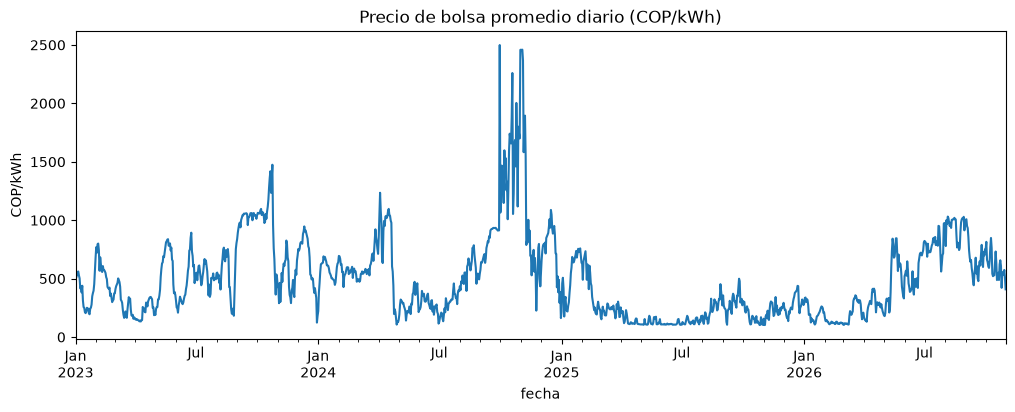

In [3]:
diario = df.groupby("fecha").precio.mean()
diario.plot(figsize=(12, 4), title="Precio de bolsa promedio diario (COP/kWh)")
plt.ylabel("COP/kWh")
plt.show()

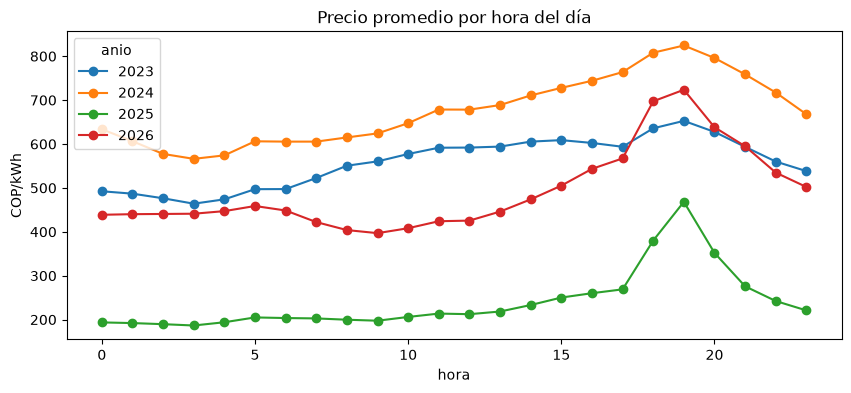

anio,2023,2024,2025,2026
hora,,,,
0,492.0,634.0,194.0,439.0
1,487.0,606.0,192.0,440.0
2,476.0,577.0,190.0,441.0
3,464.0,566.0,187.0,441.0
4,474.0,574.0,194.0,447.0
5,497.0,606.0,205.0,459.0
6,497.0,605.0,204.0,449.0
7,523.0,605.0,203.0,422.0
8,551.0,615.0,200.0,404.0


In [4]:
# perfil por hora para cada año
df["anio"] = df.fecha.dt.year
perfil = df.pivot_table(index="hora", columns="anio", values="precio", aggfunc="mean")
perfil.plot(figsize=(10, 4), marker="o", title="Precio promedio por hora del día")
plt.ylabel("COP/kWh")
plt.show()
perfil.round(0)

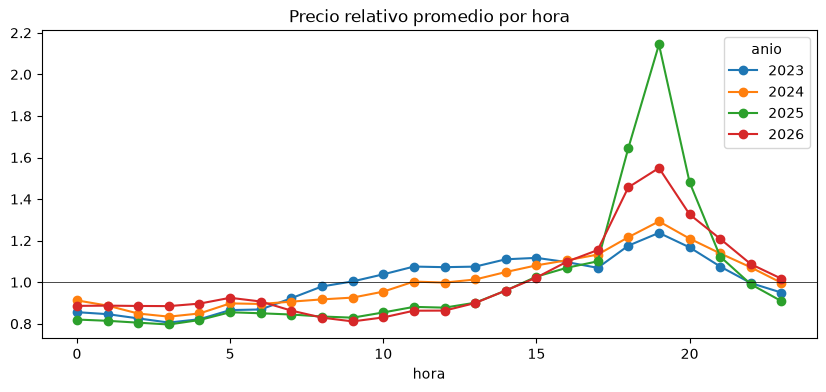

In [5]:
# el precio relativo (precio / media de las 24h anteriores) es lo que usa el MDP como estado
perfil_rel = df.pivot_table(index="hora", columns="anio", values="relativo", aggfunc="mean")
perfil_rel.plot(figsize=(10, 4), marker="o", title="Precio relativo promedio por hora")
plt.axhline(1, color="k", lw=0.5)
plt.show()

**Lo que vemos en el EDA:**

- Son 1400 días completos (33.600 horas) sin datos faltantes. El precio va de unos 96 hasta 2.676 COP/kWh, o sea que cambia muchísimo.
- El nivel general del precio cambia mucho entre años: 2024 fue carísimo (sobre todo el último trimestre, con promedio por encima de 1.100 COP/kWh) y 2025 fue muy barato (casi todo el año alrededor de 200). En 2026 vuelve a subir. Por eso no tiene sentido que el MDP use el precio en pesos como estado, porque los rangos de un año no sirven para otro. Por eso usamos el precio **relativo** a las últimas 24 horas.
- Dentro del día el patrón sí se repite: el pico es entre las 6 y las 9 p.m. (horas 18-21) todos los años. Lo que cambió es la hora más barata: en 2023-2024 era la madrugada (3-4 a.m.), pero en 2026 lo más barato es a media mañana (8-10 a.m.). Creemos que es por la entrada de plantas solares, que bajan el precio de día. Esto es importante porque una regla fija de "cargar en la madrugada" se queda desactualizada.

## 2. El MDP

- **Estado**: (hora del día 0-23, nivel de carga 0..n, rango del precio relativo de la hora anterior). El precio relativo es precio / promedio de las 24 h anteriores, y se parte en K rangos por cuantiles.
- **Acciones**: cargar, esperar, descargar (cada una mueve un paso de `potencia` MWh).
- **Transición**: la hora avanza, el nivel sube/baja con la acción y el rango de precio cambia según una matriz de transición estimada con los datos de entrenamiento (una por hora).
- **Recompensa**: cargar cuesta `precio * potencia`, descargar paga `precio * potencia * eficiencia` (las pérdidas se cargan al descargar). Se usa el precio relativo esperado dado el rango anterior, E[p_h | k_{h-1}].
- Se resuelve con iteración de valor con gamma = 0.999. Al inicio pusimos gamma = 0.95 y el MDP casi no hacía arbitraje: comprar a las 3 a.m. y vender a las 7 p.m. son 16 horas, y 0.95^16 = 0.44, entonces el descuento se comía la ganancia.

Separación temporal de los datos (nada de mezclar al azar porque es serie de tiempo):
- entrenamiento: 2023-01-01 a 2025-06-30 (para escoger K)
- validación: 2025-07-01 a 2025-12-31
- prueba: 2026-01-01 a 2026-10-31 (el modelo final se entrena con todo 2023-2025)

In [6]:
train_v = df[df.fecha < "2025-07-01"]
val = df[(df.fecha >= "2025-07-01") & (df.fecha < "2026-01-01")]
train = df[df.fecha < "2026-01-01"]
test = df[df.fecha >= "2026-01-01"]
print(len(train_v) // 24, len(val) // 24, len(train) // 24, len(test) // 24, "dias")

912 184 1096 304 dias


### Escoger K (número de rangos de precio) con validación

In [7]:
res_k = []
for K in [1, 2, 3, 5, 8]:
    mdp.K = K
    m = mdp.entrenar(train_v)
    g = mdp.simular(val, m, "mdp").ganancia.sum()
    res_k.append([K, m["iteraciones"], round(g / 1e6, 2)])
mdp.K = 3
pd.DataFrame(res_k, columns=["K", "iteraciones", "ganancia_val_millones"])

,K,iteraciones,ganancia_val_millones
0,1,8768,28.39
1,2,8742,28.38
2,3,8697,28.48
3,5,8670,27.61
4,8,8686,26.60


In [8]:
m_val = mdp.entrenar(train_v)
for p in ["ingenua", "perfil", "oraculo"]:
    print(p, round(mdp.simular(val, m_val, p).ganancia.sum() / 1e6, 2))

ingenua 28.39
perfil 28.72
oraculo 32.94


Con K = 1 el MDP no tiene información del precio, solo de la hora, y aprende básicamente lo mismo que la regla ingenua (28.39 vs 28.39, igualito). Con K = 3 es donde mejor le va en validación (28.48), y con más rangos empeora un poco, seguramente porque con más rangos hay menos datos para estimar cada fila de la matriz de transición (sobreajuste). Nos quedamos con **K = 3**.

En validación (segundo semestre de 2025) todas las políticas quedan muy cerca entre ellas y del oráculo (~86 %), porque en 2025 el precio fue muy bajo y estable y no había mucho margen para hacer arbitraje.

La iteración de valor converge en unas 8.700 iteraciones (con gamma = 0.999 converge lento, pero como está vectorizada se demora 2-3 segundos).

## 3. Resultados en prueba (2026)

Batería de 1 MWh, 0.25 MWh por hora (4 horas para llenarla), eficiencia 85 %. Líneas base:
- **ingenua**: horario fijo, carga de 1 a 4 a.m. y descarga desde las 6 p.m. (lo que uno haría "a ojo")
- **perfil**: cada día mira los últimos 30 días y carga en las 4 horas más baratas en promedio y descarga en las 4 más caras (regla adaptativa, más fuerte)
- **oráculo**: conoce todos los precios futuros y hace programación dinámica hacia atrás. Es la cota superior, no se puede lograr en la vida real.

In [9]:
import time
t = time.time()
m = mdp.entrenar(train)
print("iteraciones:", m["iteraciones"], " tiempo:", round(time.time() - t, 1), "s")

sims = {p: mdp.simular(test, m, p) for p in ["mdp", "ingenua", "perfil", "oraculo"]}
tabla = pd.DataFrame({
    "ganancia_millones": [sims[p].ganancia.sum() / 1e6 for p in sims],
    "ciclos": [(sims[p].accion == "descargar").sum() / 4 for p in sims],
}, index=list(sims))
tabla["pct_oraculo"] = 100 * tabla.ganancia_millones / tabla.loc["oraculo", "ganancia_millones"]
tabla["vs_ingenua_%"] = 100 * (tabla.ganancia_millones / tabla.loc["ingenua", "ganancia_millones"] - 1)
tabla.round(2)

iteraciones: 9165  tiempo: 2.5 s


,ganancia_millones,ciclos,pct_oraculo,vs_ingenua_%
mdp,41.60,283.00,73.64,12.45
ingenua,36.99,304.00,65.49,0.00
perfil,47.68,304.00,84.41,28.89
oraculo,56.49,238.25,100.00,52.69


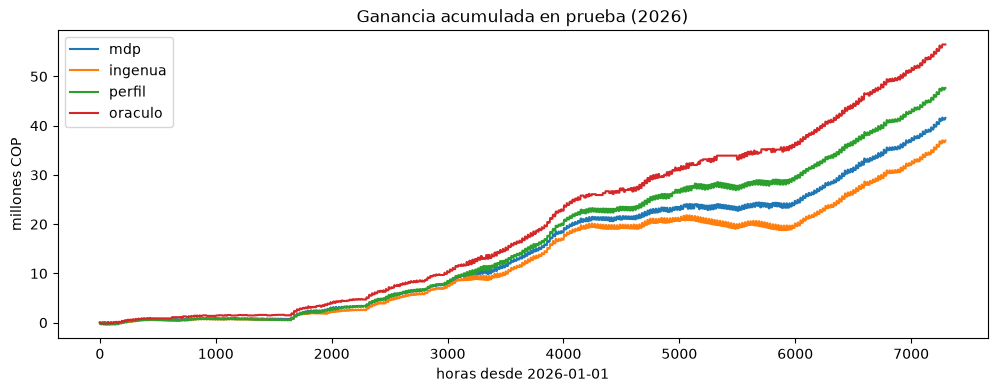

In [10]:
plt.figure(figsize=(12, 4))
for p in sims:
    plt.plot(sims[p].ganancia_acum.values / 1e6, label=p)
plt.legend()
plt.title("Ganancia acumulada en prueba (2026)")
plt.ylabel("millones COP")
plt.xlabel("horas desde 2026-01-01")
plt.show()

In [11]:
# resultado mes a mes, para ver si la diferencia es estable o depende de unos pocos meses
mes = {}
for p in sims:
    s = sims[p].copy()
    s["mes"] = s.fecha.dt.month
    mes[p] = s.groupby("mes").ganancia.sum() / 1e6
mes = pd.DataFrame(mes)
mes["mdp_gana_a_ingenua"] = mes.mdp > mes.ingenua
mes["mdp_gana_a_perfil"] = mes.mdp > mes.perfil
mes.round(2)

,mdp,ingenua,perfil,oraculo,mdp_gana_a_ingenua,mdp_gana_a_perfil
mes,,,,,,
1,0.78,0.64,0.65,1.27,True,True
2,0.06,0.03,0.03,0.30,True,True
3,2.48,1.98,2.58,3.09,True,False
4,4.25,4.24,4.40,4.97,True,False
5,5.70,4.83,6.50,7.02,True,False
6,8.14,8.17,9.00,9.64,False,False
7,2.67,1.89,4.54,6.05,True,False
8,0.25,-1.88,1.35,2.79,True,False
9,7.97,7.84,8.76,10.22,True,False


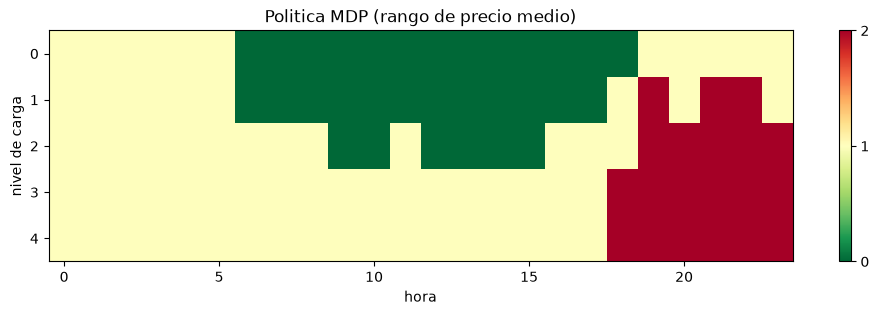

rango 0 -> horas en que carga con bateria vacia: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 23]
rango 1 -> horas en que carga con bateria vacia: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
rango 2 -> horas en que carga con bateria vacia: [13, 14, 16, 17]


In [12]:
# politica aprendida con precio en el rango del medio (verde=cargar, gris=esperar, rojo=descargar)
plt.figure(figsize=(12, 3))
plt.imshow(m["politica"][:, :, 1].T, cmap="RdYlGn_r", aspect="auto")
plt.xlabel("hora")
plt.ylabel("nivel de carga")
plt.title("Politica MDP (rango de precio medio)")
plt.colorbar(ticks=[0, 1, 2])
plt.show()
for k in range(mdp.K):
    print("rango", k, "-> horas en que carga con bateria vacia:",
          [h for h in range(24) if m["politica"][h, 0, k] == 0])

**Análisis de los resultados en prueba (enero a octubre de 2026, datos que el modelo nunca vio):**

- El MDP ganó **41,6 millones** con una batería de 1 MWh, que es **12,5 % más que la regla ingenua** (37,0 millones) y llega al 74 % de lo que se podría ganar sabiendo el futuro (oráculo, 56,5 millones). Mes a mes, el MDP le gana a la ingenua en 9 de 10 meses, entonces no es suerte de un solo mes. En agosto la ingenua incluso perdió plata (-1,88 M) y el MDP no.
- Pero la regla **perfil** (que mira los últimos 30 días) le ganó al MDP: 47,7 millones, 84 % del oráculo. Le gana en 8 de 10 meses. La razón, por lo que vimos en el EDA, es que el patrón de horas baratas cambió con los años (la madrugada dejó de ser lo más barato y ahora es la media mañana). El MDP aprendió con 2023-2025 y su matriz de transición es un promedio de esos años, mientras que el perfil se va adaptando cada día.
- La política aprendida tiene sentido: con precio "normal" carga entre las 6 a.m. y las 6 p.m. (horas solares) y descarga desde las 6 p.m. (pico de la noche); si el precio de la hora anterior estuvo bajo carga casi a cualquier hora, y si estuvo alto solo carga a las 1-5 p.m. Es decir, sí aprende a reaccionar al precio, que es algo que la regla fija no puede hacer.
- El MDP hace menos ciclos que las reglas (283 vs 304), o sea que es más selectivo: no carga si no ve que valga la pena.

## 4. Experimentos extra

In [13]:
# sensibilidad a la eficiencia de la bateria
filas = []
for ef in [0.7, 0.8, 0.85, 0.9, 0.95]:
    m_e = mdp.entrenar(train, eficiencia=ef)
    fila = [ef] + [round(mdp.simular(test, m_e, p).ganancia.sum() / 1e6, 2) for p in ["mdp", "ingenua", "perfil", "oraculo"]]
    filas.append(fila)
pd.DataFrame(filas, columns=["eficiencia", "mdp", "ingenua", "perfil", "oraculo"])

,eficiencia,mdp,ingenua,perfil,oraculo
0,0.70,16.59,6.74,17.41,34.02
1,0.80,33.10,26.91,37.59,48.30
2,0.85,41.60,36.99,47.68,56.49
3,0.90,51.21,47.08,57.77,65.42
4,0.95,60.88,57.16,67.86,75.38


In [14]:
# MDP re-entrenado cada mes con los ultimos 180 dias (para ver si el problema es que los datos cambian)
tot = 0
for ini in pd.date_range("2026-01-01", "2026-10-01", freq="MS"):
    fin = ini + pd.offsets.MonthEnd(0)
    tr = df[(df.fecha < ini) & (df.fecha >= ini - pd.Timedelta(days=180))]
    te = df[(df.fecha >= ini) & (df.fecha <= fin)]
    tot += mdp.simular(te, mdp.entrenar(tr), "mdp").ganancia.sum()
print("MDP re-entrenado mensual (180 dias):", round(tot / 1e6, 2), "millones")
print("MDP fijo (2023-2025):", round(sims["mdp"].ganancia.sum() / 1e6, 2), "millones")

MDP re-entrenado mensual (180 dias): 43.4 millones
MDP fijo (2023-2025): 41.6 millones


**Sensibilidad a la eficiencia:** el orden de las políticas se mantiene igual para todas las eficiencias (perfil > MDP > ingenua). Lo interesante es que con eficiencia baja (70 %) la regla ingenua casi no gana nada (6,7 M) porque carga y descarga todos los días aunque la diferencia de precio no alcance para cubrir las pérdidas, mientras que el MDP sí tiene en cuenta la eficiencia en la recompensa y gana 2,5 veces más (16,6 M). Ahí se ve la ventaja de modelar el problema en vez de usar una regla.

**Re-entrenar cada mes:** si se re-entrena el MDP cada mes con los últimos 180 días, la ganancia sube de 41,6 a 43,4 millones. Mejora pero no alcanza al perfil. Esto confirma que parte del problema es que los datos cambian en el tiempo (no estacionariedad), pero también que el estado que escogimos (solo el rango del precio de la hora anterior) le da poca información al MDP. El perfil de 30 días en el fondo tiene más memoria.

**Limitaciones del modelo:**
- El precio de bolsa en la realidad se conoce después (es un precio ex-post), por eso al MDP solo le dejamos ver el precio de la hora anterior. Las reglas tampoco ven el precio actual. El oráculo sí lo ve todo, por eso es cota superior.
- Suponemos que la batería es tan pequeña que no cambia el precio de bolsa (tomadora de precios), no hay costo por degradación ni por ciclo, no hay cargos de red, impuestos, ni la regulación real de cómo se remunera un SAEB (en Colombia los SAEB los despacha el CND, ver Resolución CREG 098 de 2019 que está mencionada en los documentos de la UPME del corpus).
- Discretizamos la carga en pasos fijos y el precio en 3 rangos, es una simplificación fuerte.
- Una mejora clara sería meter en el estado algo del perfil reciente (por ejemplo si la hora actual está entre las más baratas de la última semana), o usar Q-learning con más variables.